In [1]:
# Label Loading

import os, numpy as np, cv2, matplotlib.pyplot as plt
from preprocess.mpii_norm import gaze_to_3d

ROOT = "data/EyeBased/MPIIGaze"
persons = [f"p{k:02d}" for k in range(15)]

def load_meta(p):
    with open(f"{ROOT}/Label/{p}.label") as f:
        rows = [l.split() for l in f if l.strip()]
    names = rows.pop(0); ix = {n: names.index(n) for n in names}
    col = lambda n: [r[ix[n]] for r in rows]
    vec = lambda n: np.array([[float(v) for v in s.split(",")] for s in col(n)], np.float32)
    return dict(image=col("Image"), origin=col("Origin"), eye=np.array(col("WhichEye")),
                gaze=vec("2DGaze"), head=vec("2DHead"))

meta = {p: load_meta(p) for p in persons}

def angular_error(pred, gt):
    a, b = gaze_to_3d(pred), gaze_to_3d(gt)
    cos = np.sum(a*b, -1) / (np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1))
    return np.degrees(np.arccos(np.clip(cos, -1, 1)))

In [2]:
# 규모, 눈 균형, 촬영 일수, p13 중복

print("person  N    left right  days  unique(Origin,eye)")
for p in persons:
    m = meta[p]
    days = {o.split("/")[0] for o in m["origin"]}
    uniq = len(set(zip(m["origin"], m["eye"])))
    print(p, len(m["eye"]), (m["eye"]=="left").sum(), (m["eye"]=="right").sum(), len(days), uniq)

person  N    left right  days  unique(Origin,eye)
p00 3000 1500 1500 39 3000
p01 3000 1500 1500 67 3000
p02 3000 1500 1500 39 3000
p03 3000 1500 1500 65 3000
p04 3000 1500 1500 25 3000
p05 3000 1500 1500 38 3000
p06 3000 1500 1500 62 3000
p07 3000 1500 1500 56 3000
p08 3000 1500 1500 47 3000
p09 3000 1500 1500 20 3000
p10 3000 1500 1500 16 3000
p11 3000 1500 1500 19 3000
p12 3000 1500 1500 7 3000
p13 3000 1500 1500 12 2996
p14 3000 1500 1500 7 3000


### 데이터 규모와 구성
- **관찰**: 15명 모두 샘플이 3,000개이고 왼눈/오른눈이 각각 1,500개로 균형이 맞다. 촬영 일(day)수는 사람마다 7~67일(p12 및 p14 7일, p01 67일)로 크게 다르다. p13은 고유 (프레임, 눈) 조합이 2,996개로 3,000행 중 4개가 중복이다.
- **해석**: 사람별 샘플 수는 같지만 촬영 일수가 다르다. 일수가 많은 사람은 조명이나 자세 변화를 더 많이 포함할 가능성이 있다. p13의 중복은 같은 프레임의 같은 눈이 두 번 저장된 것이다.
- **의미**: 사람 간 샘플 수 불균형이 없어 15-fold 결과를 공정하게 평균할 수 있다. p13의 중복 4개는 학습용 42,000개 중 극히 일부라 영향이 작다고 보고 그대로 사용한다.

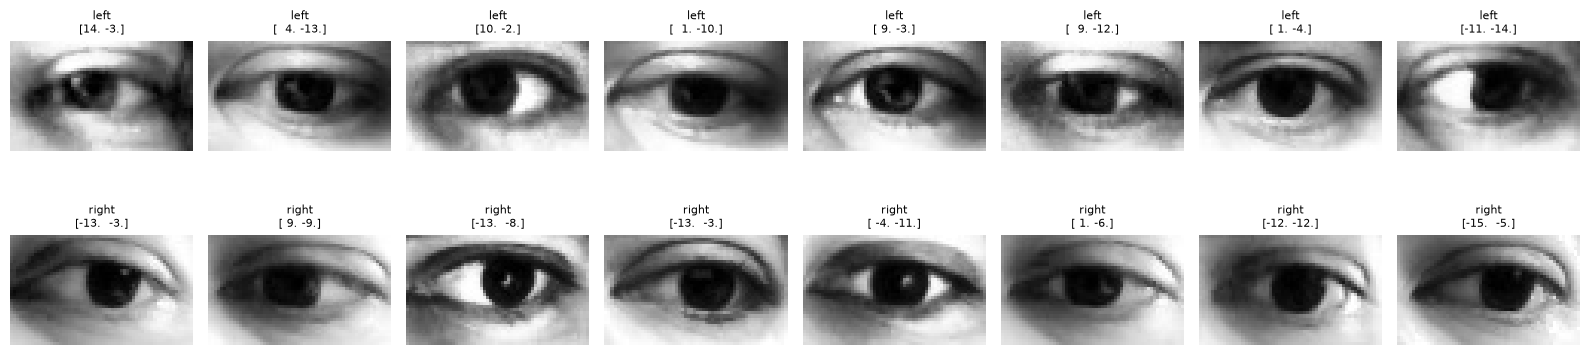

In [3]:
# Image Sample 격자

p, m = "p00", meta["p00"]
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for r, side in enumerate(["left", "right"]):
    idx = np.where(m["eye"] == side)[0][:8]
    for c, i in enumerate(idx):
        axes[r, c].imshow(cv2.imread(f"{ROOT}/Image/{m['image'][i]}", 0), cmap="gray")
        axes[r, c].set_title(f"{side}\n{np.degrees(m['gaze'][i]).round(0)}", fontsize=8); axes[r, c].axis("off")
plt.tight_layout(); plt.savefig("results/figures/eye_samples.png", dpi=150); plt.show()

### 36×60 grayscale 눈 이미지 샘플
- **관찰**: 눈이 이미지 중앙에 위치하고 크기가 비슷하게 정렬되어 있다. 윗줄의 왼눈과 아랫줄의 오른눈이 비슷한 형태로 보이며 밝기 대비가 뚜렷하다. 제목의 숫자는 [yaw(°), pitch(°)]이다.
- **해석**: 전처리가 눈 중심을 기준으로 가상 카메라를 맞추고(시점 정규화), 오른눈은 좌우 반전해 왼눈처럼 저장하며, equalizeHist로 밝기 분포를 편 결과이다.
- **의미**: 두 눈을 같은 모델에 넣어도 모양이 일관되어 하나의 모델로 학습할 수 있다. 이미지가 36×60으로 작아도 공간 구조는 남아 있으므로 CNN 필터를 적용할 수 있다.

mean(rad) [ 0.00058017 -0.15266484] std [0.15162581 0.09073563]


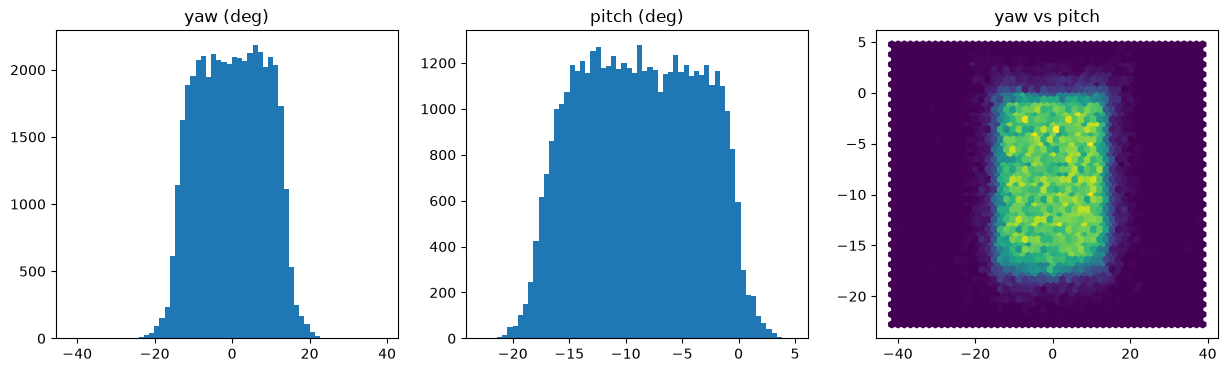

In [4]:
# 시선(gaze) 분포

allg = np.vstack([meta[p]["gaze"] for p in persons])
print("mean(rad)", allg.mean(0), "std", allg.std(0))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(np.degrees(allg[:,0]), 60); ax[0].set_title("yaw (deg)")
ax[1].hist(np.degrees(allg[:,1]), 60); ax[1].set_title("pitch (deg)")
ax[2].hexbin(np.degrees(allg[:,0]), np.degrees(allg[:,1]), gridsize=50); ax[2].set_title("yaw vs pitch")
plt.savefig("results/figures/gaze_dist.png", dpi=150); plt.show()

### 시선(gaze) 분포
- **관찰**: 전체 45,000개의 gaze 평균은 yaw 0.0006 rad(약 0.03°), pitch −0.153 rad(약 −8.7°)이고, 표준편차는 yaw 0.152 rad(약 8.7°), pitch 0.091 rad(약 5.2°)이다. yaw는 0°를 중심으로 대략 −20°~+20°, pitch는 대략 −20°~0°에 분포한다. 히스토그램은 종 모양이라기보다 가운데가 평평한 형태이고, yaw-pitch 밀도도 중심이 특별히 진하지 않은 직사각형에 가깝다.
- **해석**: 사용자가 화면 위의 정해진 영역을 보는 상황에서 수집되어 시선이 일정 범위 안에 비교적 고르게 퍼진 것으로 보인다. pitch 평균이 음수인 것은 카메라보다 아래쪽 화면을 보는 시선이 많기 때문으로 추정된다. yaw의 퍼짐(약 8.7°)이 pitch(약 5.2°)보다 크다.
- **의미**: 출력이 연속값이므로 회귀(항등 출력 + 평균 제곱 오차)가 적합하다. pitch 평균이 0이 아니므로 정답을 표준화해 학습하는 것이 유리하다. 입력을 보지 않고 평균만 내놓는 예측도 9.21°(셀 8)이므로, 모델은 이보다 확실히 낮아야 의미가 있다.

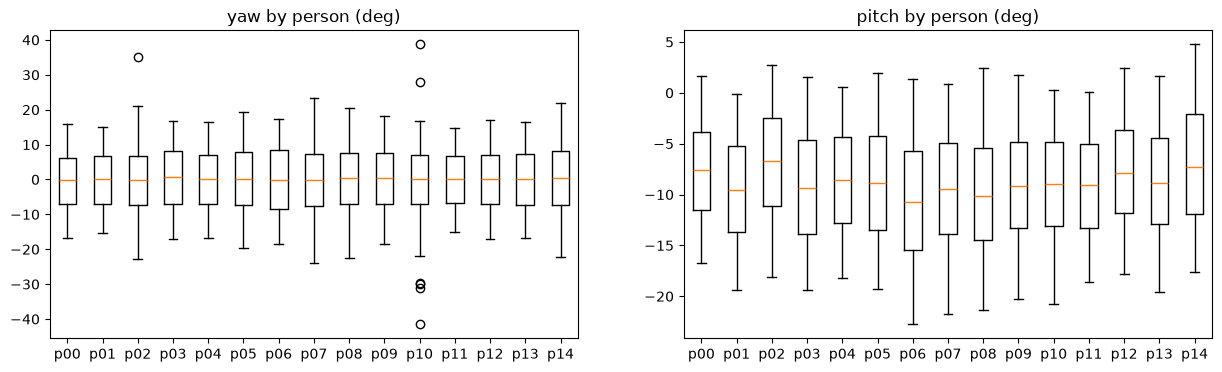

In [5]:
# 사람별 gaze (차이)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for k, name in enumerate(["yaw", "pitch"]):
    ax[k].boxplot([np.degrees(meta[p]["gaze"][:, k]) for p in persons], tick_labels=persons)
    ax[k].set_title(f"{name} by person (deg)")
plt.savefig("results/figures/gaze_by_person.png", dpi=150); plt.show()

### 사람별 gaze 분포
- **관찰**: yaw는 모든 사람의 중앙값이 0° 근처이고 박스 크기도 비슷하다. 다만 p02, p10에 yaw 이상치(최대 약 ±40°)가 보인다. pitch는 사람마다 중앙값이 약 −6.5°(p02)~−11°(p06)로 다르고 분포 범위도 다르다. 평균 예측 오차가 컸던 p06은 pitch 중앙값이 가장 낮고, p14는 pitch 상단이 +5° 근처까지 올라가 위쪽으로 넓은 편이다. 
- **해석**: yaw는 사람 간 차이가 작지만 pitch는 앉은 위치, 자세, 화면과 카메라의 상대 위치 등에 따라 중심과 폭이 달라지는 것으로 보인다. 모든 사람의 평균 하나로 예측할 때 중심이 다른 사람(p06, p14 등)에서 오차가 커졌다고 추정된다.
- **의미**: 학습에 쓰지 않은 새로운 사람에게서 성능이 떨어질 수 있으므로, 같은 사람이 학습과 시험에 섞이지 않도록 사람 단위로 나누는 leave-one-person-out 평가가 필요하다.

corr(gaze yaw,   head yaw)  : 0.11320162678163326
corr(gaze pitch, head pitch): -0.06141126448961239


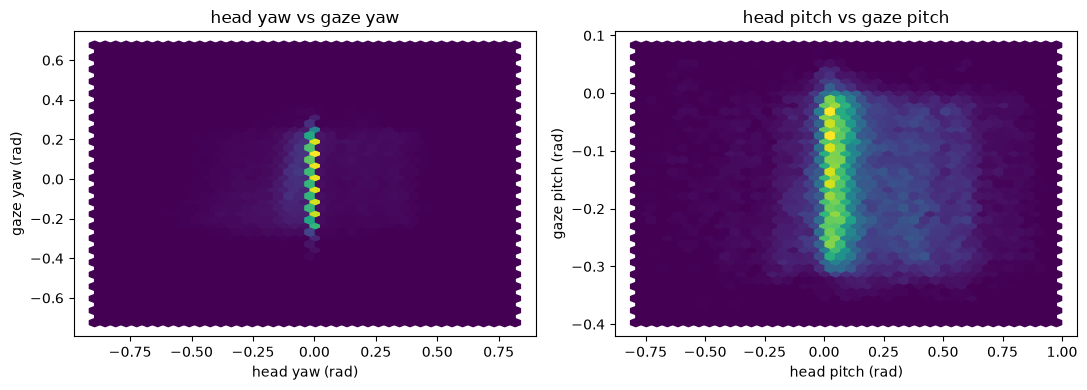

In [6]:
# head pose와 gaze의 관계

allg = np.vstack([meta[p]["gaze"] for p in persons])
allh = np.vstack([meta[p]["head"] for p in persons])

print("corr(gaze yaw,   head yaw)  :", np.corrcoef(allg[:, 0], allh[:, 0])[0, 1])
print("corr(gaze pitch, head pitch):", np.corrcoef(allg[:, 1], allh[:, 1])[0, 1])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
h0 = ax[0].hexbin(allh[:, 0], allg[:, 0], gridsize=40); ax[0].set_title("head yaw vs gaze yaw")
ax[0].set_xlabel("head yaw (rad)"); ax[0].set_ylabel("gaze yaw (rad)")
h1 = ax[1].hexbin(allh[:, 1], allg[:, 1], gridsize=40); ax[1].set_title("head pitch vs gaze pitch")
ax[1].set_xlabel("head pitch (rad)"); ax[1].set_ylabel("gaze pitch (rad)")
plt.tight_layout(); plt.savefig("results/figures/head_vs_gaze.png", dpi=150); plt.show()

### head pose와 gaze의 관계
- **관찰**: 상관계수는 yaw 0.11, pitch −0.06으로 모두 0에 가깝다. hexbin에서 head yaw/pitch 대부분이 0 근처의 좁은 띠에 몰려 있고(일부만 ±0.75 rad까지 퍼짐) 뚜렷한 선형 추세는 보이지 않는다.
- **해석**: 머리 방향만으로는 gaze를 예측하기 어렵고, 눈동자 모양(이미지)에 정보가 더 많다고 볼 수 있다. 단순 추정이나 정규화로 head pose의 변동이 줄어든 영향도 있을 수 있다. 다만 상관계수는 선형 관계만 측정하므로 비선형 관계는 알 수 없다.
- **의미**: README의 ridge 결과에서 head pose를 빼도(7.28°) 넣었을 때(7.27°)와 거의 같았던 것과 일치한다. head pose는 보조 입력으로 두고 성능은 주로 이미지에서 나올 것으로 예상한다.

gaze yaw mean   left : 0.0032  right: -0.0021
gaze pitch mean left : -0.1520  right: -0.1533


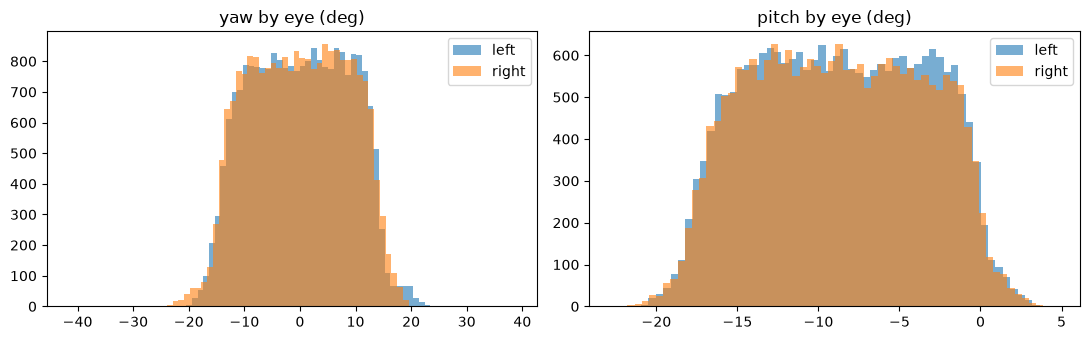


사람별 픽셀 통계 (0~1)
p00 mean 0.506  std 0.289
p01 mean 0.505  std 0.291
p02 mean 0.506  std 0.290
p03 mean 0.509  std 0.288
p04 mean 0.498  std 0.293
p05 mean 0.502  std 0.291
p06 mean 0.512  std 0.288
p07 mean 0.507  std 0.289
p08 mean 0.500  std 0.292
p09 mean 0.506  std 0.291
p10 mean 0.513  std 0.287
p11 mean 0.512  std 0.288
p12 mean 0.508  std 0.290
p13 mean 0.510  std 0.288
p14 mean 0.505  std 0.290


In [7]:
# 왼/오른쪽 눈 비교와 사람별 픽셀 통계

eye = np.concatenate([meta[p]["eye"] for p in persons])
print("gaze yaw mean   left : %.4f  right: %.4f" % (allg[eye == "left", 0].mean(), allg[eye == "right", 0].mean()))
print("gaze pitch mean left : %.4f  right: %.4f" % (allg[eye == "left", 1].mean(), allg[eye == "right", 1].mean()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(np.degrees(allg[eye == "left", 0]), 60, alpha=0.6, label="left")
ax[0].hist(np.degrees(allg[eye == "right", 0]), 60, alpha=0.6, label="right")
ax[0].set_title("yaw by eye (deg)"); ax[0].legend()
ax[1].hist(np.degrees(allg[eye == "left", 1]), 60, alpha=0.6, label="left")
ax[1].hist(np.degrees(allg[eye == "right", 1]), 60, alpha=0.6, label="right")
ax[1].set_title("pitch by eye (deg)"); ax[1].legend()
plt.tight_layout(); plt.savefig("results/figures/gaze_by_eye.png", dpi=150); plt.show()

# 사람별 픽셀 통계 (사람당 200장 샘플)
print("\n사람별 픽셀 통계 (0~1)")
for p in persons:
    idx = np.random.RandomState(0).choice(len(meta[p]["image"]), 200, replace=False)
    imgs = np.stack([cv2.imread(f"{ROOT}/Image/{meta[p]['image'][i]}", 0) for i in idx]) / 255.0
    print(p, "mean %.3f  std %.3f" % (imgs.mean(), imgs.std()))

### 왼/오른눈 비교와 픽셀 통계
- **관찰**: gaze 평균은 yaw가 왼눈 0.0032 rad, 오른눈 −0.0021 rad, pitch가 왼눈 −0.1520 rad, 오른눈 −0.1533 rad로 거의 같고, 두 히스토그램도 거의 완전히 겹친다. 사람별 픽셀 평균은 0.498~0.513, 표준편차는 0.287~0.293으로 사람 간 차이가 매우 작다.
- **해석**: 오른눈은 이미지와 gaze가 좌우 반전되어 왼눈 공간으로 저장되어 두 눈의 분포가 같아진 것이다. 픽셀 통계가 거의 같은 것은 equalizeHist가 밝기 분포를 균일하게 만든 결과이며(균일분포의 표준편차는 약 0.289), 사람 간 조명 차이가 대부분 제거되었음을 뜻한다.
- **의미**: 두 눈을 같은 모델로 학습해도 된다. 입력 표준화 통계는 학습용 14명으로만 계산한다.

In [8]:
# 하한선 검증 (README의 평균 gaze 예측 9.21도와 비교)

errs = []
for test in persons:
    mu = np.vstack([meta[p]["gaze"] for p in persons if p != test]).mean(0)   # 학습용 14명 평균만 사용
    pred = np.tile(mu, (len(meta[test]["gaze"]), 1))
    e = angular_error(pred, meta[test]["gaze"]).mean()
    errs.append(e); print(test, round(float(e), 2))
print("평균", round(float(np.mean(errs)), 2))

p00 8.43
p01 8.63
p02 9.0
p03 9.6
p04 8.97
p05 9.73
p06 10.34
p07 9.49
p08 9.61
p09 8.97
p10 8.66
p11 8.43
p12 8.6
p13 9.0
p14 10.75
평균 9.21


### 하한선(baseline) 검증: 평균 gaze 예측
- **관찰**: 입력을 보지 않고 학습용 14명의 평균 gaze만 출력해도 평균 각도 오차가 9.21°로 README 값과 같다. 가장 쉬운 사람은 8.43°인 p00과 p11, 가장 어려운 사람은 10.75°인 p14이다.
- **해석**: 같은 평균을 써도 사람마다 gaze 분포의 중심이 달라 오차가 다르다. README 값과 일치하므로 라벨 로딩과 각도 오차 계산이 올바르게 구현되었다.
- **의미**: 이후 모델은 9.21°뿐 아니라 선형 ridge baseline인 7.27°보다 낮아야 의미가 있다. fold별 난이도 차이가 있어 15개 fold를 모두 보고하고 평균으로 비교한다.

## EDA 종합과 모델링 방침
1. **문제 정의**: 눈 이미지(36*60)과 head pose를 입력으로 gaze(yaw, pitch)를 회귀, 평가는 3D 각도 오차(°)
2. **평가**: 사람 간 gaze 분포가 다르므로 15-fold leave-one-person-out으로 새 사람에 대한 일반화 측정, 테스트자의 데이터는 학습/정규화 통계/하이퍼파라미터 선택에 미사용
3. **전처리**: 이미지는 이미 정규화/equalization/0~1 스케일, 입력 표준화 통계는 학습용 14명으로만 계산
4. **입력 구성**: 이미지 2,160픽셀 + head pose 2개, head pose 효과는 제한적일 것으로 예상
5. **비교 기준**: 평균 예측 9.21°, ridge 7.27°. 교재 방식의 MLP는 15-fold 평균 7.02°를 얻었으며(`results/mlp_15fold.json`), 이후 CNN으로 확장할 예정